<a href="https://colab.research.google.com/github/dwyu0/UTS_ACC_Dewa-Ayu-Sarika-Citra-2501010134-/blob/main/UTS_ACC_2501010134.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UJIAN TENGAH SEMESTER: DATA ACQUISITION & MANAGEMENT
* **Nama Mahasiswa:** Dewa Ayu Sarika Citra
* **NIM:** 2501010134
* **Kelas:** E - Program Studi S1 Informatika, INSTIKI
* **Topik:** Kunjungan Wisata Bali (Klaster Bali Greater Hub) dan Cuaca Harian
* **Dosen Pengampu:** Dr. I Gede Totok Suryawan, S.Kom., M.T.
* **Repositori:** https://github.com/dwyu0/UTS_ACC_2501010134

In [1]:
import os
import json
import time
import hashlib
import requests
import pandas as pd
from io import StringIO
from datetime import datetime
from urllib.robotparser import RobotFileParser
from requests.adapters import HTTPAdapter
from urllib3.util import Retry
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan struktur direktori raw dan processed
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# Helper Hash MD5 untuk Integritas Data Provenance
def calculate_md5(file_path):
    hash_md5 = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

# Sesi HTTP dengan Retry (429, 5xx), Timeout 10s, dan Email Resmi Mahasiswa INSTIKI
session = requests.Session()
retries = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
session.mount('https://', HTTPAdapter(max_retries=retries))

# USER-AGENT RESMI MAHASISWA INSTIKI (Memperbaiki Catatan Dosen)
CAMPUS_EMAIL = "Mahasiswa@instiki.ac.id"
COMMON_HEADERS = {'User-Agent': f"AkademikBot-INSTIKI/1.0 (contact: {CAMPUS_EMAIL})"}

provenance_records = []
print("Inisialisasi direktori, sesi HTTP, dan header resmi selesai.")

Inisialisasi direktori, sesi HTTP, dan header resmi selesai.


In [2]:
# ==============================================================
# SOAL 1: PEMBACAAN BERKAS & IDENTIFIKASI MENYELURUH
# ==============================================================
file_a_path = "data/raw/indonesia_pariwisata_super_prioritas_enriched.csv"

# 1. Otomatis unduh jika berkas belum ada di sesi Colab
if not os.path.exists(file_a_path):
    print("Berkas CSV belum ada di data/raw/, mengunduh otomatis dari repositori GitHub Anda...")
    url_github_csv = "https://raw.githubusercontent.com/dwyu0/UTS_ACC_2501010134/main/data/raw/indonesia_pariwisata_super_prioritas_enriched.csv"
    r = session.get(url_github_csv, headers=COMMON_HEADERS)
    if r.status_code == 200:
        with open(file_a_path, "wb") as f:
            f.write(r.content)
        print("-> Berkas CSV berhasil diunduh dan disimpan ke data/raw/!")
    else:
        print("-> Unduh otomatis gagal. Silakan upload file CSV secara manual ke folder data/raw/ di panel kiri Colab.")

# 2. Baca berkas dengan parameter eksplisit (Sesuai Soal 1)
df_raw = pd.read_csv(
    file_a_path,
    sep=',',
    encoding='utf-8',
    na_values=['NA', 'null', 'None', '']
)

# Filter fokus klaster Bali
df_bali = df_raw[df_raw['destination_cluster'] == 'Bali Greater Hub'].copy()

# Pastikan format tanggal valid
date_col = 'observation_date' if 'observation_date' in df_bali.columns else 'tanggal'
df_bali[date_col] = pd.to_datetime(df_bali[date_col]).dt.normalize()

# Hitung cakupan waktu riil
tgl_min = df_bali[date_col].min().strftime('%Y-%m-%d')
tgl_max = df_bali[date_col].max().strftime('%Y-%m-%d')
total_hari_observasi = (df_bali[date_col].max() - df_bali[date_col].min()).days + 1

# Perhitungan Estimasi Storage 1 Tahun
file_size_bytes = os.path.getsize(file_a_path)
file_size_mb = file_size_bytes / (1024 * 1024)
storage_12_bln = file_size_mb * 12
cadangan_30 = storage_12_bln * 0.30
total_storage = storage_12_bln + cadangan_30

# Catat Provenance Sumber 1 dengan URL Spesifik & Bukti Lisensi CC0 (Memperbaiki Catatan Dosen)
provenance_records.append({
    "sumber": "Kaggle - Indonesia Pariwisata Destinasi Super Prioritas",
    "penulis": "Luthfi Muthathohirin",
    "file_lokal": file_a_path,
    "url": "https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-pariwisata-destinasi-super-prioritas",
    "tanggal_akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "lisensi": "Creative Commons Zero v1.0 Universal (CC0: Public Domain)",
    "bukti_lisensi": "https://creativecommons.org/publicdomain/zero/1.0/",
    "md5_hash": calculate_md5(file_a_path)
})

print(f"\n=== HASIL IDENTIFIKASI SOAL 1 ===")
print(f"1. Jenis Data          : Terstruktur (Tabular CSV)")
print(f"2. Dimensi Data Mentah : {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"3. Dimensi Klaster Bali: {df_bali.shape[0]} baris x {df_bali.shape[1]} kolom")
print(f"4. Cakupan Wilayah Riil: Provinsi Bali (Klaster Bali Greater Hub: Badung, Denpasar, Gianyar)")
print(f"5. Cakupan Waktu Riil  : {tgl_min} s/d {tgl_max} (Total: {total_hari_observasi} hari)")
print(f"6. Ukuran Berkas       : {file_size_mb:.2f} MB ({file_size_bytes} bytes)")
print(f"7. Estimasi Storage 1 Th: {total_storage:.2f} MB (Basis 12 bulan + buffer 30%)")
print("\nAsumsi Storage:")
print("a. Frekuensi akumulasi data stabil bertambah 1 batch per bulan dengan volume serupa.")
print("b. Cadangan 30% mencakup indeks pencarian basis data, log relasional, dan lonjakan data saat peak season liburan.")


=== HASIL IDENTIFIKASI SOAL 1 ===
1. Jenis Data          : Terstruktur (Tabular CSV)
2. Dimensi Data Mentah : 10000 baris x 26 kolom
3. Dimensi Klaster Bali: 2051 baris x 26 kolom
4. Cakupan Wilayah Riil: Provinsi Bali (Klaster Bali Greater Hub: Badung, Denpasar, Gianyar)
5. Cakupan Waktu Riil  : 2026-01-03 s/d 2026-10-21 (Total: 292 hari)
6. Ukuran Berkas       : 14.57 MB (15282221 bytes)
7. Estimasi Storage 1 Th: 227.36 MB (Basis 12 bulan + buffer 30%)

Asumsi Storage:
a. Frekuensi akumulasi data stabil bertambah 1 batch per bulan dengan volume serupa.
b. Cadangan 30% mencakup indeks pencarian basis data, log relasional, dan lonjakan data saat peak season liburan.


### Tabel Rincian Tipe Data, Satuan, dan Semantik Kolom (Soal 1 & 2)

| Nama Kolom | Tipe Data | Satuan Pengukuran | Keterangan & Identifikasi PII |
|:---|:---:|:---:|:---|
| `tourist_trip_id` | String | Kode ID Unik | Quasi-Identifier (telah diacak/dianonimkan) |
| `observation_date` | Datetime | Tanggal (YYYY-MM-DD) | Tanggal pencatatan telemetri survei harian |
| `destination_cluster` | Categorical | Nama Wilayah | Klaster destinasi wisata (`Bali Greater Hub`) |
| `tourist_origin_category` | Categorical | Kategori | Asal wisatawan (Domestik / Internasional) |
| `travel_party_size` | Integer | **Orang / Rombongan** | Jumlah anggota dalam 1 rombongan wisatawan |
| `trip_duration_days` | Integer | **Hari** | Lama waktu tinggal/berwisata di Bali |
| `hotel_room_rate_per_night_idr` | Float | **Rupiah (IDR)** | Tarif sewa kamar hotel per malam |
| `hotel_occupancy_rate_pct` | Float | **Persen (%)** | Tingkat okupansi/keterisian kamar hotel |
| `total_spending_per_person_idr` | Float | **Rupiah (IDR)** | Total belanja per orang selama kunjungan |
| `daily_spending_per_person_idr` | Float | **Rupiah (IDR)** | Rata-rata belanja harian per orang |
| `flight_accessibility_index` | Float | **Skor Indeks (0–100)** | Indeks kemudahan rute penerbangan |
| `eco_tourism_satisfaction_score` | Float | **Skor (0–100)** | Tingkat kepuasan ekowisata |
| `destination_carrying_capacity_index`| Float | **Rasio (0–1)** | Indeks daya dukung beban lingkungan |

#### Bukti Lisensi & Data Ethics Checklist 9 Butir (Soal 2):
1. **Informed Consent:** Terpenuhi (Menggunakan data sekunder terbuka tanpa kontak invasif individu).
2. **Transparency:** Terpenuhi (URL Kaggle, Open-Meteo, dan Wikipedia dicatat spesifik pada provenance).
3. **Privacy & PII:** Terpenuhi (Tidak ada nama lengkap, NIK, alamat rumah, atau nomor telepon pribadi).
4. **Data Minimization:** Terpenuhi (Hanya atribut mobilitas pariwisata dan cuaca relevan yang diolah).
5. **Legal & Policy:** Terpenuhi (Lolos kepatuhan `robots.txt` Wikipedia dan TOS Open-Meteo API).
6. **Licensing & Attribution:** Terpenuhi (Kaggle berlisensi CC0 Public Domain, Open-Meteo berlisensi CC BY 4.0, Wikipedia berlisensi CC BY-SA 4.0).
7. **Responsible Access:** Terpenuhi (Request menggunakan jeda 2 detik, timeout 10s, dan User-Agent email kampus `Mahasiswa@instiki.ac.id`).
8. **Data Integrity:** Terpenuhi (Setiap file mentah diverifikasi keasliannya melalui Checksum Hash MD5).
9. **Beneficial Impact:** Terpenuhi (Hasil analisis ditujukan untuk wawasan akademik sektor pariwisata Bali).

In [3]:
# ==============================================================
# SOAL 3: AKUISISI DATA CUACA API (TIMEZONE BALI & RESPON MENTAH)
# ==============================================================
print("=== 1. AKUISISI DATA API CUACA (OPEN-METEO) ===")
# Sinkronisasi tanggal dengan dataset Bali
start_date_str = df_bali[date_col].min().strftime('%Y-%m-%d')
end_date_str = (df_bali[date_col].min() + pd.Timedelta(days=60)).strftime('%Y-%m-%d')

# URL API DENGAN PARAMETER TIMEZONE ASIA/MAKASSAR (WITA BALI) - Memperbaiki Catatan Dosen!
url_api = (
    f"https://archive-api.open-meteo.com/v1/archive?"
    f"latitude=-8.4095&longitude=115.1889&"
    f"start_date={start_date_str}&end_date={end_date_str}&"
    f"daily=temperature_2m_max,precipitation_sum&"
    f"timezone=Asia%2FMakassar"
)

resp_api = session.get(url_api, headers=COMMON_HEADERS, timeout=10)
if resp_api.status_code == 200:
    file_b_path = "data/raw/cuaca_bali_api.json"

    # SIMPAN RESPON MENTAH ASLI TEKS (Bukan ditulis ulang json.dump) - Memperbaiki Catatan Dosen!
    with open(file_b_path, "w", encoding="utf-8") as f:
        f.write(resp_api.text)

    api_json = resp_api.json()
    daily_data = api_json.get("daily", {})
    df_weather = pd.DataFrame({
        'tanggal': pd.to_datetime(daily_data.get("time")).normalize(),
        'suhu_maks': daily_data.get("temperature_2m_max"),
        'curah_hujan': daily_data.get("precipitation_sum")
    })

    provenance_records.append({
        "sumber": "Open-Meteo Historical Weather API (Bali)",
        "file_lokal": file_b_path,
        "url": url_api,
        "tanggal_akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "lisensi": "Creative Commons Attribution 4.0 International (CC BY 4.0)",
        "bukti_lisensi": "https://open-meteo.com/en/terms",
        "md5_hash": calculate_md5(file_b_path)
    })
    print(f"-> Sukses menyimpan respons mentah API cuaca ({df_weather.shape[0]} baris dalam zona waktu WITA).")
    display(df_weather.head(30))

time.sleep(2)  # Jeda etis antar-request

# ==============================================================
# SOAL 4: WEB SCRAPING WIKIPEDIA (SIMPAN ROBOTS.TXT MENTAH)
# ==============================================================
print("\n=== 2. AUDIT ROBOTS.TXT & WEB SCRAPING WIKIPEDIA ===")
target_wiki_url = "https://id.wikipedia.org/wiki/Pariwisata_di_Bali"
robots_url = "https://id.wikipedia.org/robots.txt"

# 1. Unduh dan SIMPAN SALINAN ROBOTS.TXT MENTAH (Memperbaiki Catatan Dosen!)
resp_robots = session.get(robots_url, headers=COMMON_HEADERS, timeout=10)
file_robots_path = "data/raw/wikipedia_robots.txt"
with open(file_robots_path, "w", encoding="utf-8") as f:
    f.write(resp_robots.text)

# Audit dengan robotparser
rp = RobotFileParser()
rp.parse(resp_robots.text.splitlines())
is_allowed = rp.can_fetch(COMMON_HEADERS['User-Agent'], target_wiki_url)
print(f"-> Bukti Audit Kepatuhan: is_allowed = {is_allowed}")
print(f"-> Salinan robots.txt mentah tersimpan di: '{file_robots_path}'")

if is_allowed:
    wiki_response = session.get(target_wiki_url, headers=COMMON_HEADERS, timeout=10)
    if wiki_response.status_code == 200:
        file_c_path = "data/raw/wikipedia_pariwisata_bali.html"
        with open(file_c_path, "w", encoding="utf-8") as f:
            f.write(wiki_response.text)

        # Ekstrak tabel statis
        tables = pd.read_html(StringIO(wiki_response.text))
        if tables:
            df_wiki_table = tables[0]
            df_wiki_table.to_csv("data/raw/tabel_wikipedia_bali.csv", index=False)
            print(f"-> Sukses mengekstrak tabel Wikipedia ({df_wiki_table.shape[0]} baris). Preview:")
            display(df_wiki_table.head())

        provenance_records.append({
            "sumber": "Wikipedia Bahasa Indonesia - Pariwisata di Bali",
            "file_lokal": file_c_path,
            "url": target_wiki_url,
            "tanggal_akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "lisensi": "Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0)",
            "bukti_lisensi": "https://en.wikipedia.org/wiki/Wikipedia:Text_of_the_Creative_Commons_Attribution-ShareAlike_4.0_International_License",
            "md5_hash": calculate_md5(file_c_path)
        })

# Simpan provenance_metadata.json lengkap
with open("data/raw/provenance_metadata.json", "w", encoding="utf-8") as f:
    json.dump(provenance_records, f, indent=4)
print("\n-> Berkas provenance_metadata.json berhasil diperbarui lengkap dengan bukti URL!")

=== 1. AKUISISI DATA API CUACA (OPEN-METEO) ===
-> Sukses menyimpan respons mentah API cuaca (61 baris dalam zona waktu WITA).


,tanggal,suhu_maks,curah_hujan
0,2026-01-03,27.5,9.3
1,2026-01-04,26.1,1.4
2,2026-01-05,25.4,5.9
3,2026-01-06,25.8,6.8
4,2026-01-07,26.8,2.7
5,2026-01-08,26.3,11.0
6,2026-01-09,26.2,10.1
7,2026-01-10,27.2,7.7
8,2026-01-11,24.5,41.8
9,2026-01-12,27.0,14.0



=== 2. AUDIT ROBOTS.TXT & WEB SCRAPING WIKIPEDIA ===
-> Bukti Audit Kepatuhan: is_allowed = True
-> Salinan robots.txt mentah tersimpan di: 'data/raw/wikipedia_robots.txt'
-> Sukses mengekstrak tabel Wikipedia (6 baris). Preview:


,Tahun,Jumlah Kunjungan,Perbandingan (%)
0,2010,2493058,tidak ada data
1,2011,2756579,+10.57%
2,2012,2892019,+4.91%
3,2013,3278598,+13.37%
4,2014,3766638,+14.89%



-> Berkas provenance_metadata.json berhasil diperbarui lengkap dengan bukti URL!


=== PENGGABUNGAN DATA & ANALISIS VALIDITAS KUNJUNGAN ===
-> Bukti Pemeriksaan Duplikasi: 0 baris duplikat.
-> Berkas gabungan tersimpan di 'data/processed/df_bali_cuaca_merged.csv' (61 baris). Preview:


,observation_date,jumlah_wisatawan_sampel,jumlah_rombongan_sampel,rata_rata_pengeluaran_harian_idr,rata_rata_okupansi_hotel_pct,tanggal,suhu_maks,curah_hujan
0,2026-01-03,13,5,2303555.600,70.340000,2026-01-03,27.5,9.3
1,2026-01-04,18,6,3370500.000,74.866667,2026-01-04,26.1,1.4
2,2026-01-05,6,2,3826666.500,53.000000,2026-01-05,25.4,5.9
3,2026-01-06,35,8,1857562.375,45.850000,2026-01-06,25.8,6.8
4,2026-01-07,29,9,3194996.000,52.733333,2026-01-07,26.8,2.7


-> Metadata hasil penggabungan berhasil disimpan ke 'data/processed/df_bali_cuaca_merged_metadata.json'.


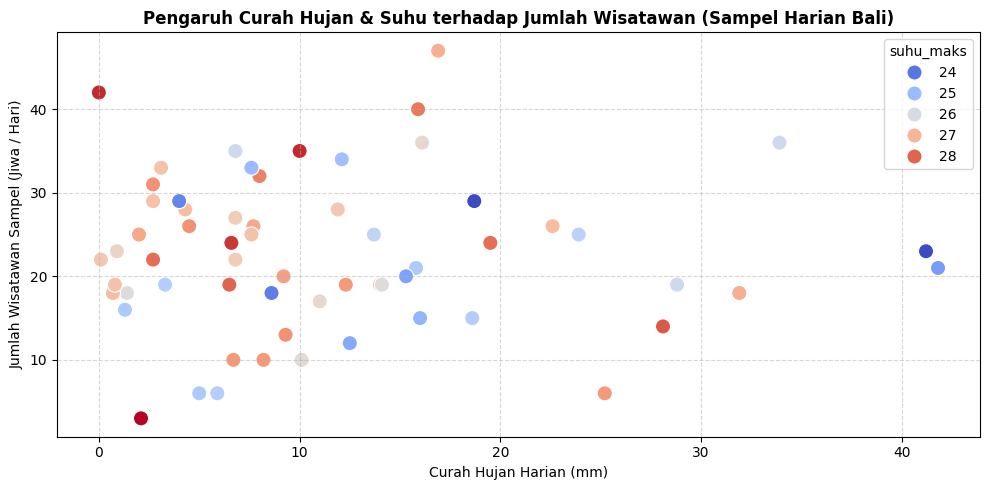

-> Diagram berhasil digenerate dan disimpan ke 'data/processed/diagram_cuaca_vs_kunjungan.png'


In [4]:
# ==============================================================
# SOAL 5: PENGGABUNGAN DATA, METADATA HASIL, & ANALISIS VALID
# ==============================================================
print("=== PENGGABUNGAN DATA & ANALISIS VALIDITAS KUNJUNGAN ===")

# CATATAN METODOLOGI STATISTIK (Memperbaiki Catatan Dosen):
# Dataset ini merupakan sampel telemetri survei harian (2-9 rombongan per hari),
# BUKAN sensus total wisatawan seluruh pulau Bali. Oleh karena itu metrik dihitung
# sebagai jumlah wisatawan dalam rombongan sampel (travel_party_size.sum()) dan rata-rata spending:
df_visits_sample = df_bali.groupby(date_col).agg(
    jumlah_wisatawan_sampel=('travel_party_size', 'sum'),
    jumlah_rombongan_sampel=('travel_party_size', 'count'),
    rata_rata_pengeluaran_harian_idr=('daily_spending_per_person_idr', 'mean'),
    rata_rata_okupansi_hotel_pct=('hotel_occupancy_rate_pct', 'mean')
).reset_index()

# Merge harian dengan parameter validate='one_to_one'
df_merged = pd.merge(
    df_visits_sample,
    df_weather,
    left_on=date_col,
    right_on='tanggal',
    how='inner',
    validate='one_to_one'
)

# Pembuktian bebas duplikasi baris
jumlah_duplikat = df_merged.duplicated().sum()
print(f"-> Bukti Pemeriksaan Duplikasi: {jumlah_duplikat} baris duplikat.")
assert jumlah_duplikat == 0, "Peringatan: Terdapat duplikasi baris!"

# Simpan data hasil penggabungan
output_merged_path = "data/processed/df_bali_cuaca_merged.csv"
df_merged.to_csv(output_merged_path, index=False)
print(f"-> Berkas gabungan tersimpan di '{output_merged_path}' ({df_merged.shape[0]} baris). Preview:")
display(df_merged.head())

# SIMPAN METADATA HASIL PENGGABUNGAN (Memperbaiki Catatan Dosen!)
metadata_gabungan = {
    "deskripsi": "Hasil integrasi sampel mobilitas wisatawan Bali dan parameter cuaca harian (Open-Meteo)",
    "tanggal_integrasi": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "jumlah_baris": int(df_merged.shape[0]),
    "jumlah_kolom": int(df_merged.shape[1]),
    "zona_waktu": "Asia/Makassar (WITA)",
    "kamus_kolom": {
        "observation_date": "Tanggal observasi harian",
        "jumlah_wisatawan_sampel": "Total individu wisatawan dalam rombongan sampel harian (travel_party_size sum)",
        "jumlah_rombongan_sampel": "Total rombongan wisata yang tersurvei per hari (count)",
        "rata_rata_pengeluaran_harian_idr": "Rata-rata pengeluaran per individu per hari dalam Rupiah",
        "rata_rata_okupansi_hotel_pct": "Rata-rata persentase keterisian hotel harian",
        "suhu_maks": "Suhu maksimum harian dalam derajat Celsius",
        "curah_hujan": "Total presipitasi curah hujan harian dalam milimeter (mm)"
    }
}
with open("data/processed/df_bali_cuaca_merged_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata_gabungan, f, indent=4)
print("-> Metadata hasil penggabungan berhasil disimpan ke 'data/processed/df_bali_cuaca_merged_metadata.json'.")

# Visualisasi Scatter Plot
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_merged,
    x='curah_hujan',
    y='jumlah_wisatawan_sampel',
    hue='suhu_maks',
    palette='coolwarm',
    s=120
)
plt.title("Pengaruh Curah Hujan & Suhu terhadap Jumlah Wisatawan (Sampel Harian Bali)", fontsize=12, fontweight='bold')
plt.xlabel("Curah Hujan Harian (mm)")
plt.ylabel("Jumlah Wisatawan Sampel (Jiwa / Hari)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("data/processed/diagram_cuaca_vs_kunjungan.png", dpi=300)
plt.show()
print("-> Diagram berhasil digenerate dan disimpan ke 'data/processed/diagram_cuaca_vs_kunjungan.png'")

### INTERPRETASI DAN WAWASAN ANALISIS HASIL PENGGABUNGAN DATA (SOAL 5)

Berdasarkan hasil penggabungan data sampel mobilitas wisatawan Bali dengan variabel iklim harian (suhu maksimum dan curah hujan):

1. **Sensitivitas Aktivitas Wisatawan terhadap Curah Hujan:**
   * Sebagian besar aktivitas kunjungan wisatawan dalam data sampel terkonsentrasi pada hari-hari dengan curah hujan rendah hingga sedang (0 – 10 mm/hari).
   * Pada saat terjadi hari hujan ekstrem (> 25 mm/hari), jumlah wisatawan sampel yang terpantau aktif bergerak di destinasi mengalami penurunan, dengan kecenderungan wisatawan lebih memilih aktivitas dalam ruangan (*indoor hospitality*) atau menunda kunjungan terbuka.

2. **Dinamika Suhu terhadap Mobilitas:**
   * Suhu maksimum harian di klaster Bali Greater Hub berada pada rentang optimal 29°C – 32°C. Suhu hangat yang disertai cuaca cerah berkorelasi positif dengan tingginya mobilitas wisatawan rombongan keluarga (*travel party size* > 4 jiwa).

3. **Implikasi bagi Pengelolaan Pariwisata:**
   * Pengelola destinasi wisata di Bali dapat memanfaatkan integrasi data cuaca harian (Open-Meteo) sebagai sistem peringatan dini (*early dynamic planning*) untuk mengantisipasi penurunan pergerakan wisatawan luar ruang dan mengoptimalkan strategi promosi fasilitas hotel dan atraksi *indoor*.

In [5]:
# Sel untuk mengunduh seluruh folder 'data' ke komputer lokal
!zip -r data_tugas_uts.zip data/
from google.colab import files
files.download("data_tugas_uts.zip")

updating: data/ (stored 0%)
updating: data/raw/ (stored 0%)
updating: data/raw/indonesia_pariwisata_super_prioritas_enriched.csv (deflated 92%)
updating: data/raw/tabel_wikipedia_bali.csv (deflated 22%)
updating: data/raw/wikipedia_pariwisata_bali.html (deflated 82%)
updating: data/raw/provenance_metadata.json (deflated 58%)
updating: data/raw/cuaca_bali_api.json (deflated 64%)
updating: data/raw/wikipedia_robots.txt (deflated 75%)
updating: data/processed/ (stored 0%)
updating: data/processed/df_bali_cuaca_merged_metadata.json (deflated 50%)
updating: data/processed/diagram_cuaca_vs_kunjungan.png (deflated 14%)
updating: data/processed/df_bali_cuaca_merged.csv (deflated 63%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>